# MVA WGS + VCF Early Exploration (Quality Check)

This notebook performs **basic technical profiling and exploratory analysis** of VCF and WGS-derived files (FASTQ, BAM, or CRAM). It is designed to stream/chunk large files rather than load a whole genome into RAM.

**Important:** these plots support data QC and candidate discovery; they do not diagnose Mosaic Variegated Aneuploidy (MVA). Confirm findings with validated clinical pipelines and orthogonal testing.


## 1. Kaggle setup
Enable Internet only if package installation requires it. Kaggle input datasets are mounted read-only under `/kaggle/input`; outputs belong in `/kaggle/working`.

In [2]:
import shutil
import subprocess
import sys

missing_hts = [tool for tool in ('bcftools', 'samtools', 'tabix') if shutil.which(tool) is None]
if missing_hts and shutil.which('apt-get'):
    subprocess.run(['apt-get', 'update', '-qq'], check=True)
    subprocess.run(['apt-get', 'install', '-y', '-qq', 'bcftools', 'samtools', 'tabix'], check=True, stdout=subprocess.DEVNULL)
    missing_hts = [tool for tool in ('bcftools', 'samtools', 'tabix') if shutil.which(tool) is None]
if missing_hts:
    print('Missing HTS tools:', ', '.join(missing_hts), '| install with Homebrew or apt before VCF/BAM sections.')
try:
    import cyvcf2  # noqa: F401
    import seaborn  # noqa: F401
    import upsetplot  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'cyvcf2', 'seaborn', 'upsetplot'], check=True)
print('Setup complete')

Setup complete


In [5]:
from pathlib import Path
from collections import Counter, defaultdict
import os, re, json, gzip, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from cyvcf2 import VCF

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 100)
path_work = '/Users/macbookpro/Documents/RA/mva-hackathon'
WORK = Path(path_work) if Path(path_work).exists() else Path.cwd() / 'results'
INPUT = Path(path_work + '/input') if Path(path_work + '/input').exists() else Path.cwd() / 'data' / 'raw'
OUT = WORK / 'results/mva_early_insights'
OUT.mkdir(parents=True, exist_ok=True)
print('Input:', INPUT)
print('Output:', OUT)

Input: /Users/macbookpro/Documents/RA/mva-hackathon/input
Output: /Users/macbookpro/Documents/RA/mva-hackathon/mva_early_insights


## 2. Discover and select files
The code detects VCF/VCF.GZ, BAM/CRAM, and FASTQ files. If several exist, manually replace the selected paths below.

In [6]:
def find_files(root, endings):
    return sorted(p for p in root.rglob('*') if p.is_file() and any(str(p).lower().endswith(e) for e in endings))

vcfs = find_files(INPUT, ('.vcf', '.vcf.gz'))
alignments = find_files(INPUT, ('.bam', '.cram'))
fastqs = find_files(INPUT, ('.fastq', '.fq', '.fastq.gz', '.fq.gz'))
inventory = pd.DataFrame([
    {'type': kind, 'path': str(p), 'size_GB': round(p.stat().st_size / 1e9, 3)}
    for kind, paths in [('VCF', vcfs), ('BAM/CRAM', alignments), ('FASTQ', fastqs)] for p in paths
])
display(inventory if len(inventory) else 'No supported files found under /kaggle/input')

VCF_PATH = vcfs[0] if vcfs else None       # change if needed
ALIGNMENT_PATH = alignments[0] if alignments else None
FASTQ_PATHS = fastqs[:2]                   # typically paired R1/R2
print('VCF:', VCF_PATH)
print('Alignment:', ALIGNMENT_PATH)
print('FASTQ:', FASTQ_PATHS)

,type,path,size_GB
0,VCF,/Users/macbookpro/Documents/RA/mva-hackathon/i...,0.315


VCF: /Users/macbookpro/Documents/RA/mva-hackathon/input/WGS_EX2312012_HGWCNDSX7.vcf.gz
Alignment: None
FASTQ: []


In [12]:
# check the reference
# !bcftools view -h "$VCF_PATH" | grep -E "reference|contig"

# sneakpeek actual variants
# !bcftools view -H "$VCF_PATH" | head

# check genotype fields
!bcftools query \
-f '%CHROM\t%POS\t%REF\t%ALT\t%FILTER[\t%GT\t%DP\t%GQ]\n' \
"$VCF_PATH" | head

1	13273	G	C	MQ40	1/1	13	39
1	13417	C	CGAGA	MQ40	1/1	8	24
1	14248	T	G	MQ40	0/1	13	88
1	14354	C	A	LowQual;MQ40;QD2	0/1	16	39
1	14590	G	A	MQ40	0/1	10	99
1	14599	T	A	MQ40	0/1	11	99
1	14604	A	G	MQ40	0/1	11	99
1	14610	T	C	MQ40	0/1	11	99
1	14653	C	T	MQ40	0/1	28	99
1	14773	C	T	MQ40	0/1	28	99
[query_vcf] Error: cannot write to standard output


In [17]:
# Download the zipped GRCh38 primary assembly from Ensembl
!wget ftp://ftp.ensembl.org/pub/release-110/fasta/homo_sapiens/dna/Homo_sapiens.GRCh38.dna.primary_assembly.fa.gz

# Decompress the file to get the raw .fa file
!gunzip Homo_sapiens.GRCh38.dna.primary_assembly.fa.gz


--2026-09-18 23:05:59--  ftp://ftp.ensembl.org/pub/release-110/fasta/homo_sapiens/dna/Homo_sapiens.GRCh38.dna.primary_assembly.fa.gz
           => ‘Homo_sapiens.GRCh38.dna.primary_assembly.fa.gz’
Resolving ftp.ensembl.org (ftp.ensembl.org)... 193.62.193.169
Connecting to ftp.ensembl.org (ftp.ensembl.org)|193.62.193.169|:21... connected.
Logging in as anonymous ... Logged in!
==> SYST ... done.    ==> PWD ... done.
==> TYPE I ... done.  ==> CWD (1) /pub/release-110/fasta/homo_sapiens/dna ... done.
==> SIZE Homo_sapiens.GRCh38.dna.primary_assembly.fa.gz ... 881964081
==> PASV ... done.    ==> RETR Homo_sapiens.GRCh38.dna.primary_assembly.fa.gz ... done.
Length: 881964081 (841M) (unauthoritative)

Homo_sapiens.GRCh38 100%[===================>] 841.11M   843KB/s    in 8m 22s  

2026-09-18 23:14:25 (1.67 MB/s) - ‘Homo_sapiens.GRCh38.dna.primary_assembly.fa.gz’ saved [881964081]



In [30]:
# bcftools stats reports quantities including variant counts, SNP/indel statistics, Ti/Tv, allele-frequency distributions, depth distributions and per-sample statistics.
!bcftools stats -s - "$VCF_PATH" > patient.stats

In [19]:
# normalization
# split multiallelic sites + left-normalizes indels + standardizes REF/ALT representation
# output: [E::faidx_adjust_position] The sequence "M" was not found faidx_fetch_seq failed at M:263 [W::bgzf_read_block] EOF marker is absent. The input may be truncated
!bcftools norm \
    -f Homo_sapiens.GRCh38.dna.primary_assembly.fa \
    -m -any \
    "$VCF_PATH" \
    -Oz \
    -o normalized.vcf.gz

!tabix -p vcf normalized.vcf.gz

[E::faidx_adjust_position] The sequence "M" was not found
faidx_fetch_seq failed at M:263
[W::bgzf_read_block] EOF marker is absent. The input may be truncated


In [31]:
!bcftools index -t normalized.vcf.gz

[E::main_vcfindex] the index file exists. Please use '-f' to overwrite normalized.vcf.gz.tbi


In [33]:
# examine genotype evidence explicitly
!bcftools query \
-f '%CHROM\t%POS\t%REF\t%ALT\t%QUAL\t%FILTER[\t%GT\t%DP\t%GQ\t%AD]\n' \
normalized.vcf.gz \
> genotype_qc.tsv

[W::bcf_sr_add_hreader] No BGZF EOF marker; file 'normalized.vcf.gz' may be truncated
Error: no BGZF EOF marker; file may be truncated


## 3. VCF integrity, header, samples, and index
A compressed VCF is copied to working storage before indexing because `/kaggle/input` is read-only. Re-indexing also resolves old indexes that lack count metadata.

In [8]:
if VCF_PATH:
    selected_vcf = VCF_PATH
    if str(VCF_PATH).endswith('.vcf.gz'):
        selected_vcf = WORK / VCF_PATH.name
        if not selected_vcf.exists():
            subprocess.run(['cp', str(VCF_PATH), str(selected_vcf)], check=True)
        subprocess.run(['bcftools', 'index', '-f', '-t', str(selected_vcf)], check=True)
    check = subprocess.run(['bcftools', 'view', '-h', str(selected_vcf)], capture_output=True, text=True)
    assert check.returncode == 0, check.stderr
    reader = VCF(str(selected_vcf))
    print('Samples:', reader.samples or '[site-only VCF]')
    print('Sequence names:', len(reader.seqnames))
    print('First contigs:', reader.seqnames[:10])
    print('Reference header:', [x for x in reader.raw_header.splitlines() if x.startswith('##reference=')][:1])
else:
    selected_vcf = None
    print('No VCF selected; skip VCF sections.')

Samples: ['WGS_EX2312012']
Sequence names: 2580
First contigs: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']
Reference header: ['##reference=file://refGenome/GCA_000001405.15_GRCh38_no_alt_analysis_set_plus_hs38d1_maskedGRC_exclusions_v2_no_chr.fasta']


## 4. Stream VCF into compact summary tables
This gathers aggregate counts, genotype summaries, quality/depth samples, and annotation fields when available. `MAX_METRIC_POINTS` limits plotting memory, but all variants still contribute to counts.

In [9]:
MAX_METRIC_POINTS = 250_000
MVA_GENES = {'BUB1B', 'CEP57', 'TRIP13'}
KNOWN_MVA_RELATED = MVA_GENES | {'BUB1', 'MAD2L1', 'CDC20', 'CENPE', 'KNL1', 'NDC80', 'PLK1', 'AURKB'}

counts = Counter(); chrom_counts = Counter(); filter_counts = Counter(); consequence_counts = Counter()
sample_gt = defaultdict(Counter); qual_values, dp_values, af_values = [], [], []
candidate_rows = []

def variant_type(ref, alts):
    if len(ref) == 1 and all(len(a) == 1 for a in alts): return 'SNV'
    if any(a.startswith('<') or '[' in a or ']' in a for a in alts): return 'SV-symbolic'
    if all(len(a) != len(ref) for a in alts): return 'INDEL'
    return 'MNV/complex'

if selected_vcf:
    v = VCF(str(selected_vcf))
    samples = v.samples
    for rec in v:
        alts = [a for a in rec.ALT if a and a != '.']
        if not alts: continue
        vt = variant_type(rec.REF, alts)
        counts['variants'] += 1; counts[vt] += 1; chrom_counts[rec.CHROM] += 1
        filter_counts[rec.FILTER or 'PASS'] += 1
        if vt == 'SNV':
            pair = (rec.REF.upper(), alts[0].upper())
            if pair in {('A','G'),('G','A'),('C','T'),('T','C')}: counts['transition'] += 1
            else: counts['transversion'] += 1
        if rec.QUAL is not None and len(qual_values) < MAX_METRIC_POINTS: qual_values.append(rec.QUAL)
        dp = rec.INFO.get('DP')
        if dp is not None and len(dp_values) < MAX_METRIC_POINTS: dp_values.append(float(dp))
        af = rec.INFO.get('AF')
        if af is not None and len(af_values) < MAX_METRIC_POINTS:
            af_values.extend(np.atleast_1d(af).astype(float).tolist())
        for s, gt in zip(samples, rec.genotypes):
            alleles = gt[:-1]
            if any(a < 0 for a in alleles): label = 'missing'
            elif len(set(alleles)) == 1 and alleles[0] == 0: label = 'hom_ref'
            elif len(set(alleles)) == 1: label = 'hom_alt'
            else: label = 'het'
            sample_gt[s][label] += 1
        ann_text = ' '.join(str(rec.INFO.get(k) or '') for k in ('ANN','CSQ','BCSQ'))
        genes_hit = sorted(g for g in KNOWN_MVA_RELATED if re.search(rf'(?<![A-Z0-9]){g}(?![A-Z0-9])', ann_text.upper()))
        for term in ('stop_gained','frameshift_variant','splice_acceptor_variant','splice_donor_variant','missense_variant'):
            if term in ann_text: consequence_counts[term] += 1
        if genes_hit:
            candidate_rows.append({'CHROM':rec.CHROM,'POS':rec.POS,'REF':rec.REF,'ALT':','.join(alts),
                                   'QUAL':rec.QUAL,'FILTER':rec.FILTER or 'PASS','genes':','.join(genes_hit),
                                   'annotation_excerpt':ann_text[:500]})
    v.close()

    overview = pd.Series(counts, name='count').to_frame()
    overview.loc['Ti/Tv', 'count'] = counts['transition'] / max(counts['transversion'], 1)
    display(overview)
    gt_df = pd.DataFrame(sample_gt).T.fillna(0).astype(int)
    display(gt_df)
    pd.DataFrame(candidate_rows).to_csv(OUT/'mva_gene_hits_unfiltered.csv', index=False)
else:
    print('Skipped')

,count
variants,5.012204e+06
SNV,4.082023e+06
transversion,1.386428e+06
INDEL,9.255630e+05
transition,2.695595e+06
MNV/complex,4.618000e+03
Ti/Tv,1.944273e+00


,hom_alt,het
WGS_EX2312012,1898267,3113937


## 5. VCF visualizations
Interpret these as technical signals: chromosome distribution, variant composition, filters, quality/depth, and per-sample genotype composition. Extreme patterns can indicate calling, normalization, sex-chromosome, or contig-label issues.

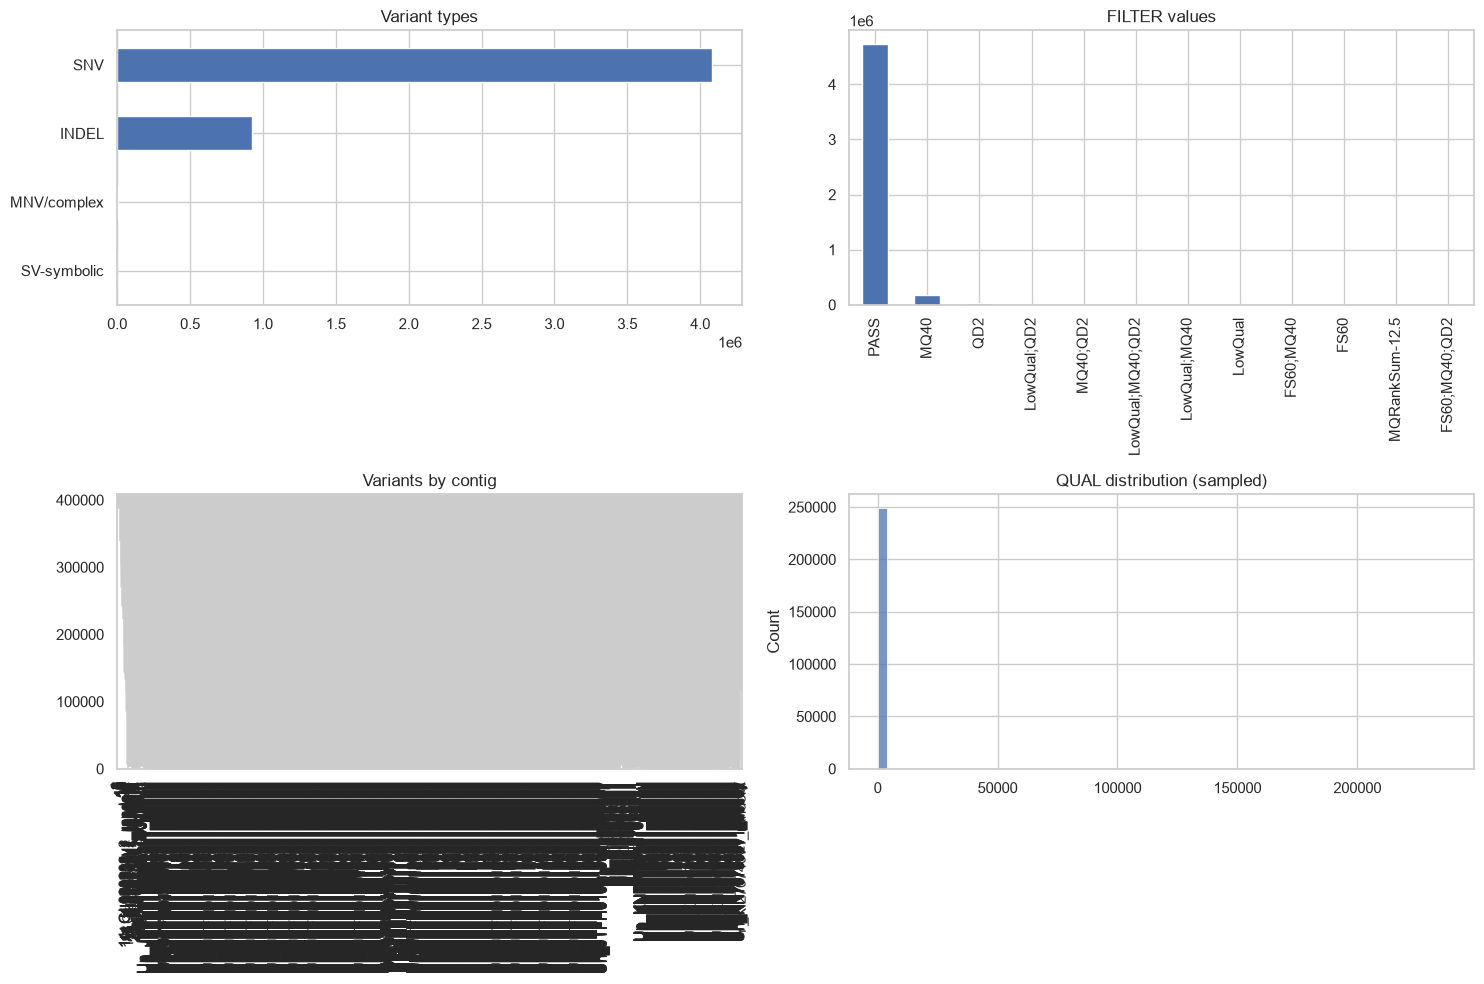

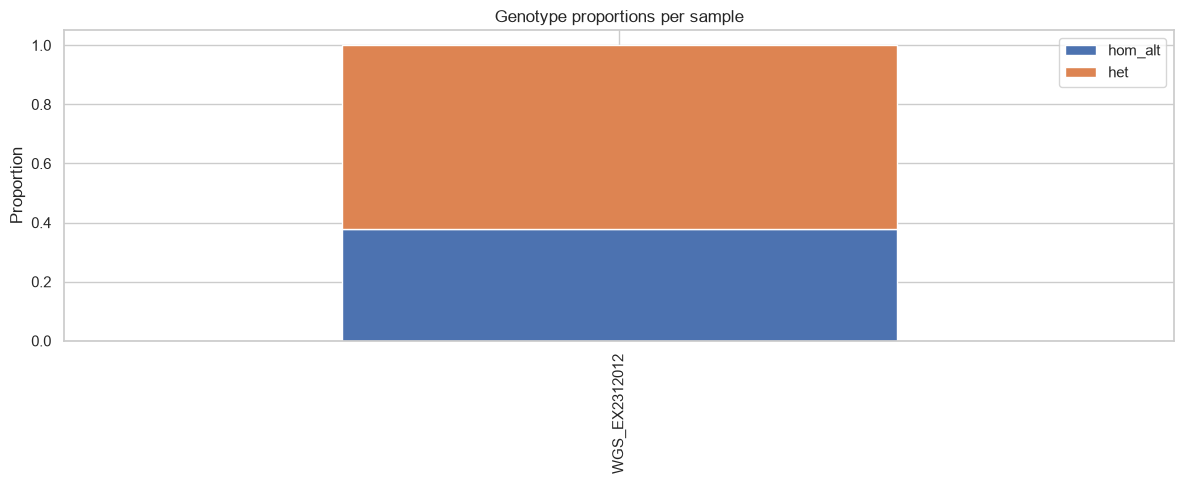

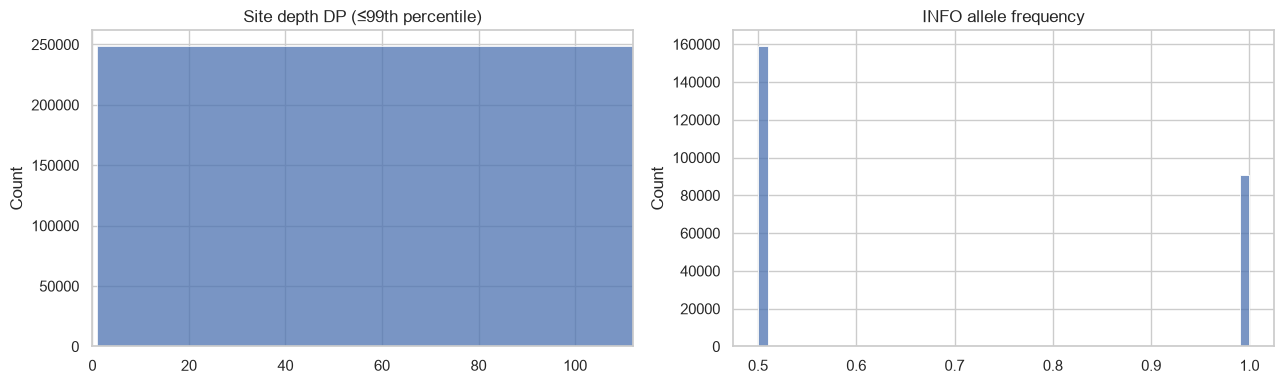

In [10]:
if selected_vcf:
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    pd.Series({k:counts[k] for k in ('SNV','INDEL','MNV/complex','SV-symbolic')}).sort_values().plot.barh(ax=axes[0,0], title='Variant types')
    pd.Series(filter_counts).sort_values(ascending=False).head(12).plot.bar(ax=axes[0,1], title='FILTER values')
    chrom_order = sorted(chrom_counts, key=lambda x: (not str(x).replace('chr','').isdigit(), int(str(x).replace('chr','')) if str(x).replace('chr','').isdigit() else 999, str(x)))
    pd.Series(chrom_counts).reindex(chrom_order).plot.bar(ax=axes[1,0], title='Variants by contig')
    if qual_values: sns.histplot(qual_values, bins=60, ax=axes[1,1]); axes[1,1].set_title('QUAL distribution (sampled)')
    plt.tight_layout(); plt.savefig(OUT/'vcf_overview.png', dpi=160, bbox_inches='tight'); plt.show()

    if len(gt_df):
        gt_df.div(gt_df.sum(axis=1), axis=0).plot.bar(stacked=True, figsize=(12,5), title='Genotype proportions per sample')
        plt.ylabel('Proportion'); plt.tight_layout(); plt.savefig(OUT/'genotype_proportions.png', dpi=160); plt.show()
    if dp_values or af_values:
        fig, axes = plt.subplots(1, 2, figsize=(13,4))
        if dp_values: sns.histplot(dp_values, bins=60, ax=axes[0]); axes[0].set_xlim(0, np.percentile(dp_values, 99)); axes[0].set_title('Site depth DP (≤99th percentile)')
        if af_values: sns.histplot(af_values, bins=50, ax=axes[1]); axes[1].set_title('INFO allele frequency')
        plt.tight_layout(); plt.savefig(OUT/'vcf_depth_af.png', dpi=160); plt.show()

## 6. Annotation and MVA-oriented first pass
The gene-hit table only works if the VCF already has `ANN`, `CSQ`, or `BCSQ`. A hit is **not causal evidence**. For MVA, later analysis must examine rare damaging biallelic variants (including compound heterozygotes) in genes such as `BUB1B`, `CEP57`, and `TRIP13`, plus CNV/SV and phenotype/inheritance evidence.

In [11]:
if selected_vcf:
    candidates = pd.DataFrame(candidate_rows)
    print('MVA-related annotated records:', len(candidates))
    display(candidates.head(50) if len(candidates) else 'No gene hits found. The VCF may be unannotated.')
    if consequence_counts:
        pd.Series(consequence_counts).sort_values().plot.barh(figsize=(8,4), title='Selected predicted consequences')
        plt.tight_layout(); plt.savefig(OUT/'consequences.png', dpi=160); plt.show()
    print('Next: annotate with VEP/SnpEff, population AF (gnomAD), ClinVar, CADD/REVEL/SpliceAI, then test inheritance using the trio.')

MVA-related annotated records: 0


'No gene hits found. The VCF may be unannotated.'

Next: annotate with VEP/SnpEff, population AF (gnomAD), ClinVar, CADD/REVEL/SpliceAI, then test inheritance using the trio.


## 7. BAM/CRAM profiling
This checks alignment summary, insert size/error statistics, and coverage sampled every 10 kb. CRAM generally needs the exact reference FASTA; set `REFERENCE_FASTA` when required. Coverage from one tissue can suggest large CNVs/aneuploidy, but low-level mosaicism needs a dedicated method and validation.

In [12]:
REFERENCE_FASTA = None  # e.g. Path('/kaggle/input/grch38-reference/Homo_sapiens_assembly38.fasta')
if ALIGNMENT_PATH:
    ref_args = ['--reference', str(REFERENCE_FASTA)] if REFERENCE_FASTA else []
    flagstat = subprocess.run(['samtools','flagstat',*ref_args,str(ALIGNMENT_PATH)], capture_output=True, text=True)
    print(flagstat.stdout if flagstat.returncode == 0 else flagstat.stderr)
    stats_path = OUT/'samtools_stats.txt'
    with open(stats_path, 'w') as f:
        r = subprocess.run(['samtools','stats',*ref_args,str(ALIGNMENT_PATH)], stdout=f, stderr=subprocess.PIPE, text=True)
    if r.returncode: print(r.stderr)
    # Sparse depth: one queried base per 10 kb, much cheaper than whole-base depth.
    header = subprocess.run(['samtools','view','-H',*ref_args,str(ALIGNMENT_PATH)], capture_output=True, text=True, check=True).stdout
    regions = OUT/'sparse_positions.bed'
    with open(regions, 'w') as f:
        for line in header.splitlines():
            if line.startswith('@SQ'):
                fields = dict(x.split(':',1) for x in line.split('\t')[1:])
                name, length = fields['SN'], int(fields['LN'])
                if re.fullmatch(r'(chr)?([1-9]|1[0-9]|2[0-2]|X|Y)', name):
                    for pos in range(0, length, 10_000): f.write(f'{name}\t{pos}\t{pos+1}\n')
    depth_cmd = ['samtools','depth','-a','-b',str(regions),*ref_args,str(ALIGNMENT_PATH)]
    depth = subprocess.run(depth_cmd, capture_output=True, text=True, check=True).stdout
    depth_df = pd.DataFrame([x.split('\t') for x in depth.splitlines()], columns=['chrom','pos','depth'])
    depth_df[['pos','depth']] = depth_df[['pos','depth']].astype(int)
    chrom_depth = depth_df.groupby('chrom').depth.agg(['median','mean','count']).sort_index()
    display(chrom_depth)
    chrom_depth['median'].plot.bar(figsize=(13,4), title='Sparse median depth by chromosome (10 kb grid)')
    plt.ylabel('Depth'); plt.tight_layout(); plt.savefig(OUT/'alignment_chromosome_depth.png', dpi=160); plt.show()
else:
    print('No BAM/CRAM selected; skip this section.')

No BAM/CRAM selected; skip this section.


## 8. FASTQ raw-read profiling
This samples the first 200,000 reads per FASTQ for read length, mean base quality, GC%, and N%. It is fast and useful for early QC, but FastQC/MultiQC should be used for a full report.

In [13]:
def sample_fastq(path, max_reads=200_000):
    opener = gzip.open if str(path).endswith('.gz') else open
    rows = []
    with opener(path, 'rt', errors='replace') as f:
        for i in range(max_reads):
            name, seq, plus, qual = f.readline(), f.readline().strip(), f.readline(), f.readline().strip()
            if not qual: break
            rows.append((len(seq), np.mean([ord(c)-33 for c in qual]), (seq.upper().count('G')+seq.upper().count('C'))/max(len(seq),1), seq.upper().count('N')/max(len(seq),1)))
    return pd.DataFrame(rows, columns=['read_length','mean_phred','gc_fraction','n_fraction'])

fastq_summaries = []
for fq in FASTQ_PATHS:
    q = sample_fastq(fq)
    fastq_summaries.append({'file':fq.name,'sampled_reads':len(q),'mean_length':q.read_length.mean(),
                            'mean_phred':q.mean_phred.mean(),'mean_GC':q.gc_fraction.mean(),'reads_with_N_pct':100*(q.n_fraction>0).mean()})
    fig, axes = plt.subplots(1,3,figsize=(15,4))
    sns.histplot(q.read_length, bins=50, ax=axes[0]); axes[0].set_title(f'{fq.name}: read length')
    sns.histplot(q.mean_phred, bins=50, ax=axes[1]); axes[1].set_title('Mean Phred quality')
    sns.histplot(q.gc_fraction, bins=50, ax=axes[2]); axes[2].set_title('GC fraction')
    plt.tight_layout(); plt.savefig(OUT/f'{fq.name}_fastq_qc.png', dpi=160); plt.show()
display(pd.DataFrame(fastq_summaries) if fastq_summaries else 'No FASTQ selected; skip this section.')

'No FASTQ selected; skip this section.'

## 9. Save compact outputs and interpretation checklist

**Questions for early insight**
1. Are call counts, Ti/Tv, PASS proportion, depth, and heterozygosity plausible for this caller and file scope?
2. Is this single-sample or trio data, and can recessive/compound-heterozygous inheritance be tested?
3. Is the VCF annotated and does it contain SNV/indel only, or also CNV/SV calls?
4. Are rare damaging variants present in `BUB1B`, `CEP57`, `TRIP13`, or related mitotic-checkpoint genes?
5. Do BAM depth and allele balance show chromosome-level or mosaic abnormalities that merit dedicated CNV/SV/mosaic analysis?
6. Do candidate variants match the child's HPO phenotype and segregation evidence?

In [14]:
if selected_vcf:
    pd.Series(counts, name='count').to_csv(OUT/'vcf_counts.csv')
    pd.Series(chrom_counts, name='count').to_csv(OUT/'variants_by_contig.csv')
    pd.Series(filter_counts, name='count').to_csv(OUT/'filter_counts.csv')
    if len(gt_df): gt_df.to_csv(OUT/'sample_genotype_counts.csv')
print('Generated outputs:')
for p in sorted(OUT.iterdir()): print('-', p.name)
print('\nDownload files from Kaggle > Output after Save Version.')

Generated outputs:
- filter_counts.csv
- genotype_proportions.png
- mva_gene_hits_unfiltered.csv
- sample_genotype_counts.csv
- variants_by_contig.csv
- vcf_counts.csv
- vcf_depth_af.png
- vcf_overview.png

Download files from Kaggle > Output after Save Version.


## 10. Extended Interpretation: File output analysis

| File                           | Main question                                         |
| ------------------------------ | ----------------------------------------------------- |
| `vcf_counts.csv`               | How many SNVs/indels/etc. are present?                |
| `filter_counts.csv`            | How many calls PASS QC?                               |
| `variants_by_contig.csv`       | Are variants distributed sensibly across chromosomes? |
| `sample_genotype_counts.csv`   | How many het/hom-alt/missing genotypes?               |
| `genotype_proportions.png`     | Visual genotype balance                               |
| `genotype_qc.tsv`              | Are individual genotypes supported by good DP/GQ/VAF? |
| `patient.stats`                | Whole-VCF bcftools QC summary                         |
| `vcf_depth_af.png`             | Depth and allele-fraction distribution                |
| `vcf_overview.png`             | High-level visual summary                             |
| `mva_gene_hits_unfiltered.csv` | Are variants present in known MVA-related genes?      |
| `normalized.vcf.gz`            | Clean VCF to send into VEP                            |
| `.tbi`                         | Index only; nothing to interpret biologically         |


In [42]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULT_DIR = WORK / "results" / "mva_early_insights"

files = {
    "vcf_counts": RESULT_DIR / "vcf_counts.csv",
    "filter_counts": RESULT_DIR / "filter_counts.csv",
    "variants_by_contig": RESULT_DIR / "variants_by_contig.csv",
    "sample_genotypes": RESULT_DIR / "sample_genotype_counts.csv",
    "genotype_qc": RESULT_DIR / "genotype_qc.tsv",
    # "mva_hits": RESULT_DIR / "mva_gene_hits_unfiltered.csv", this csv null
    "patient_stats": RESULT_DIR / "patient.stats",
}

def load_table(path):
    if not path.exists():
        print(f"Missing: {path}")
        return None

    sep = "\t" if path.suffix == ".tsv" else ","
    return pd.read_csv(path, sep=sep)

tables = {}

for name, path in files.items():
    if name == "patient_stats":
        continue

    df = load_table(path)
    tables[name] = df

    if df is not None:
        print("\n" + "="*80)
        print(name)
        print("shape:", df.shape)
        print("columns:", list(df.columns))
        display(df.head(10))


vcf_counts
shape: (6, 2)
columns: ['Unnamed: 0', 'count']


,Unnamed: 0,count
0,variants,5012204
1,SNV,4082023
2,transversion,1386428
3,INDEL,925563
4,transition,2695595
5,MNV/complex,4618



filter_counts
shape: (35, 2)
columns: ['Unnamed: 0', 'count']


,Unnamed: 0,count
0,MQ40,177522
1,LowQual;MQ40;QD2,10240
2,MQ40;QD2,12541
3,PASS,4740790
4,LowQual;MQ40,9782
5,LowQual;QD2,17000
6,QD2,35402
7,FS60,834
8,LowQual,6081
9,FS60;QD2,55



variants_by_contig
shape: (1690, 2)
columns: ['Unnamed: 0', 'count']


...


sample_genotypes
shape: (1, 3)
columns: ['Unnamed: 0', 'hom_alt', 'het']


,Unnamed: 0,hom_alt,het
0,WGS_EX2312012,1898267,3113937


/var/folders/kd/60d16wd1309b3n63310hvnw00000gn/T/ipykernel_63122/3387866815.py:24: DtypeWarning: Columns (0: 1) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, sep=sep)



genotype_qc
shape: (4961810, 10)
columns: ['1', '13273', 'G', 'C', '385.77', 'MQ40', '1/1', '13', '39', '0,13']


,1,13273,G,C,385.77,MQ40,1/1,13,39,"0,13"
0,1,13417,C,CGAGA,320.75,MQ40,1/1,8,24,"0,8"
1,1,14248,T,G,59.77,MQ40,0/1,13,88,"8,5"
2,1,14354,C,A,11.12,LowQual;MQ40;QD2,0/1,16,39,"13,3"
3,1,14590,G,A,76.77,MQ40,0/1,10,99,"7,3"
4,1,14599,T,A,73.77,MQ40,0/1,11,99,"8,3"
5,1,14604,A,G,73.77,MQ40,0/1,11,99,"8,3"
6,1,14610,T,C,70.77,MQ40,0/1,11,99,"8,3"
7,1,14653,C,T,208.77,MQ40,0/1,28,99,"16,12"
8,1,14773,C,T,249.77,MQ40,0/1,28,99,"16,12"
9,1,14795,C,G,30.77,MQ40;QD2,0/1,20,59,"15,5"


In [44]:
# what types of variants are in the VCF?
df = tables["vcf_counts"]

display(df)

if df is not None:
    print("\nNumeric summary")
    display(df.describe(include="all"))

,Unnamed: 0,count
0,variants,5012204
1,SNV,4082023
2,transversion,1386428
3,INDEL,925563
4,transition,2695595
5,MNV/complex,4618



Numeric summary


,Unnamed: 0,count
count,6,6.000000e+00
unique,6,NaN
top,variants,NaN
freq,1,NaN
mean,NaN,2.351072e+06
std,NaN,1.932096e+06
min,NaN,4.618000e+03
25%,NaN,1.040779e+06
50%,NaN,2.041012e+06
75%,NaN,3.735416e+06


In [47]:
# calculate proportions filter for QC checks
# 95% PASS means most variants satisfy the variant caller's filtering criteria 
df = tables["filter_counts"].copy()

# find likely count column
count_cols = [
    c for c in df.columns
    if "count" in c.lower() or "n_" in c.lower()
]

if count_cols:
    count_col = count_cols[0]

    df["proportion"] = df[count_col] / df[count_col].sum()
    df["percent"] = df["proportion"] * 100

display(df)

,Unnamed: 0,count,proportion,percent
0,MQ40,177522,3.541795e-02,3.541795
1,LowQual;MQ40;QD2,10240,2.043013e-03,0.204301
2,MQ40;QD2,12541,2.502093e-03,0.250209
3,PASS,4740790,9.458494e-01,94.584937
4,LowQual;MQ40,9782,1.951636e-03,0.195164
5,LowQual;QD2,17000,3.391721e-03,0.339172
6,QD2,35402,7.063160e-03,0.706316
7,FS60,834,1.663939e-04,0.016639
8,LowQual,6081,1.213239e-03,0.121324
9,FS60;QD2,55,1.097322e-05,0.001097


,Unnamed: 0,count
0,1,383428
1,2,388761
2,3,321840
3,4,339607
4,5,289812
...,...,...
1685,Un_JTFH01001994v1_decoy,5
1686,Un_JTFH01001995v1_decoy,72
1687,Un_JTFH01001996v1_decoy,23
1688,Un_JTFH01001997v1_decoy,72


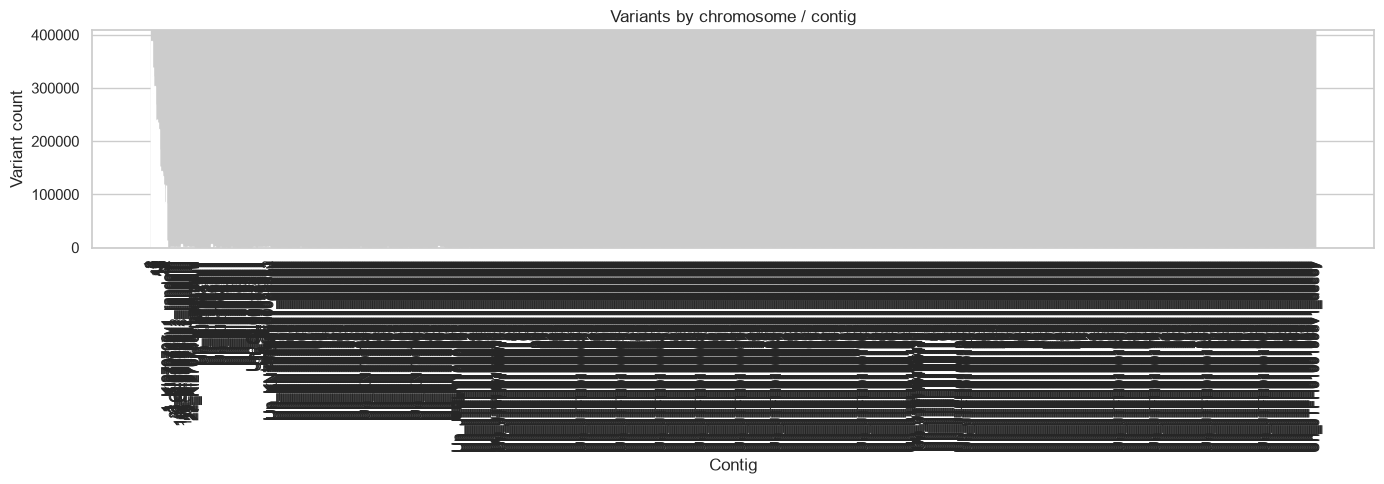

In [50]:
# checks whether variants appear across chromosomes as expected
df = tables["variants_by_contig"]
display(df)
if df is not None:
    # identify likely columns
    chrom_col = next(
        (c for c in df.columns
         if c.lower() in ["chrom", "chromosome", "contig", "#chrom"]),
        df.columns[0]
    )

    count_col = next(
        (c for c in df.columns
         if "count" in c.lower() or "variant" in c.lower()),
        df.columns[-1]
    )

    plt.figure(figsize=(14, 5))
    plt.bar(df[chrom_col].astype(str), df[count_col])
    plt.xticks(rotation=90)
    plt.ylabel("Variant count")
    plt.xlabel("Contig")
    plt.title("Variants by chromosome / contig")
    plt.tight_layout()
    plt.show()

! How to interpret the contig viz?

In [52]:
# ! i think we should rethinking this file formed and what it should interpret 
df = tables["sample_genotypes"]

display(df)

,Unnamed: 0,hom_alt,het
0,WGS_EX2312012,1898267,3113937


In [54]:
# more QC
gt = tables["genotype_qc"].copy()

headers = [
    "CHROM", "POS", "REF", "ALT", "QUAL",
    "FILTER", "GT", "DP", "GQ", "AD"
]

assert gt.shape[1] == len(headers), \
    f"Expected {len(headers)} columns, but got {gt.shape[1]}"

gt.columns = headers

print(gt.shape)
display(gt.head())
display(gt.describe(include="all"))

(4961810, 10)


,CHROM,POS,REF,ALT,QUAL,FILTER,GT,DP,GQ,AD
0,1,13417,C,CGAGA,320.75,MQ40,1/1,8,24,"0,8"
1,1,14248,T,G,59.77,MQ40,0/1,13,88,"8,5"
2,1,14354,C,A,11.12,LowQual;MQ40;QD2,0/1,16,39,"13,3"
3,1,14590,G,A,76.77,MQ40,0/1,10,99,"7,3"
4,1,14599,T,A,73.77,MQ40,0/1,11,99,"8,3"


,CHROM,POS,REF,ALT,QUAL,FILTER,GT,DP,GQ,AD
count,4961810.0,4.961810e+06,4961810,4961810,4.961810e+06,4961810,4961810,4.961810e+06,4.961810e+06,4961810
unique,25.0,NaN,39155,36650,NaN,33,3,NaN,NaN,23379
top,2.0,NaN,C,C,NaN,PASS,0/1,NaN,NaN,"0,43"
freq,394288.0,NaN,1203298,1167395,NaN,4727539,3013054,NaN,NaN,70616
mean,NaN,7.669876e+07,NaN,NaN,9.082878e+02,NaN,NaN,4.269751e+01,9.458549e+01,NaN
std,NaN,5.629777e+07,NaN,NaN,1.561344e+03,NaN,NaN,7.397355e+01,1.519400e+01,NaN
min,NaN,1.021600e+04,NaN,NaN,1.015000e+01,NaN,NaN,0.000000e+00,0.000000e+00,NaN
25%,NaN,3.038406e+07,NaN,NaN,4.967300e+02,NaN,NaN,3.400000e+01,9.900000e+01,NaN
50%,NaN,6.608250e+07,NaN,NaN,7.257700e+02,NaN,NaN,4.200000e+01,9.900000e+01,NaN
75%,NaN,1.128741e+08,NaN,NaN,1.297730e+03,NaN,NaN,4.900000e+01,9.900000e+01,NaN


In [55]:
# calculating VAF

def parse_ad(ad):
    try:
        parts = str(ad).replace("[", "").replace("]", "").split(",")
        values = [float(x) for x in parts]

        if len(values) >= 2:
            ref = values[0]
            alt = sum(values[1:])
            total = ref + alt

            return alt / total if total > 0 else np.nan
    except:
        pass

    return np.nan

ad_col = next(
    (c for c in gt.columns if c.upper() == "AD"),
    None
)

if ad_col:
    gt["VAF"] = gt[ad_col].apply(parse_ad)

display(gt.head())

,CHROM,POS,REF,ALT,QUAL,FILTER,GT,DP,GQ,AD,VAF
0,1,13417,C,CGAGA,320.75,MQ40,1/1,8,24,"0,8",1.000000
1,1,14248,T,G,59.77,MQ40,0/1,13,88,"8,5",0.384615
2,1,14354,C,A,11.12,LowQual;MQ40;QD2,0/1,16,39,"13,3",0.187500
3,1,14590,G,A,76.77,MQ40,0/1,10,99,"7,3",0.300000
4,1,14599,T,A,73.77,MQ40,0/1,11,99,"8,3",0.272727


count    4.961810e+06
mean     4.269751e+01
std      7.397355e+01
min      0.000000e+00
1%       5.000000e+00
5%       1.600000e+01
10%      2.300000e+01
25%      3.400000e+01
50%      4.200000e+01
75%      4.900000e+01
90%      5.600000e+01
95%      6.100000e+01
99%      9.600000e+01
max      2.420000e+04
Name: DP, dtype: float64


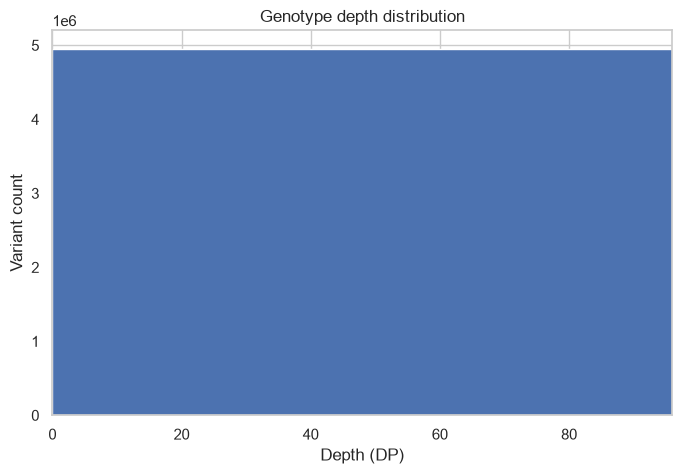

In [56]:
dp_col = next(
    (c for c in gt.columns if c.upper() == "DP"),
    None
)

if dp_col:
    dp = pd.to_numeric(gt[dp_col], errors="coerce")

    print(dp.describe(percentiles=[
        .01, .05, .10, .25, .50, .75, .90, .95, .99
    ]))

    plt.figure(figsize=(8,5))
    plt.hist(dp.dropna(), bins=100)
    plt.xlabel("Depth (DP)")
    plt.ylabel("Variant count")
    plt.title("Genotype depth distribution")
    plt.xlim(0, dp.quantile(.99))
    plt.show()

With known around this standard, it shows fairly coherent depth distribution which shows that many genotype calls had high sequence support
standard median DP/our = 32/42
standard 10th percentile/our = 20/23
standard 90th percentile/our = 47/56
However, extremely high depth : max in 2420 need to investigate more because highly repetitive regions can generate abnormal mapping depth.

count    4.961810e+06
mean     9.458549e+01
std      1.519400e+01
min      0.000000e+00
1%       1.600000e+01
5%       6.000000e+01
10%      9.000000e+01
25%      9.900000e+01
50%      9.900000e+01
75%      9.900000e+01
90%      9.900000e+01
95%      9.900000e+01
99%      9.900000e+01
max      9.900000e+01
Name: GQ, dtype: float64

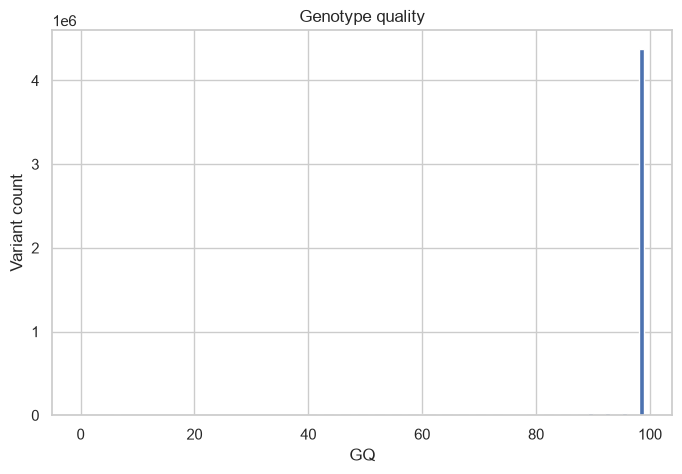

In [59]:
# genotype quality
gq_col = next(
    (c for c in gt.columns if c.upper() == "GQ"),
    None
)

if gq_col:
    gq = pd.to_numeric(gt[gq_col], errors="coerce")

    display(gq.describe(
        percentiles=[.01,.05,.1,.25,.5,.75,.9,.95,.99]
    ))

    plt.figure(figsize=(8,5))
    plt.hist(gq.dropna(), bins=100)
    plt.xlabel("GQ")
    plt.ylabel("Variant count")
    plt.title("Genotype quality")
    plt.show()

high GQ -> genotype assignment strongly supported
low GQ -> 0/1 versus 0/0 versus 1/1 uncertain

For disease candidate analysis I would especially inspect candidate variants individually rather than treating GQ as only a global statistic.

! need to explore more what does it means

Heterozygous variants: 3079394
Hom-alt variants: 1882416

Heterozygous VAF:


count    3.079299e+06
mean     5.042288e-01
std      1.548055e-01
min      0.000000e+00
25%      4.285714e-01
50%      5.000000e-01
75%      5.625000e-01
max      1.000000e+00
Name: VAF, dtype: float64

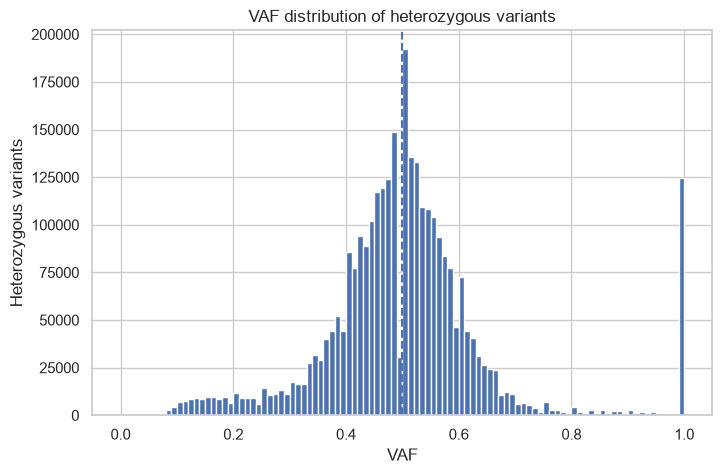

In [60]:
# VAF by genotype
gt_col = next(
    (c for c in gt.columns
     if c.upper() in ["GT", "GENOTYPE"]),
    None
)

if gt_col and "VAF" in gt.columns:

    het = gt[
        gt[gt_col].astype(str).isin(
            ["0/1", "1/0", "0|1", "1|0"]
        )
    ]

    hom_alt = gt[
        gt[gt_col].astype(str).isin(
            ["1/1", "1|1"]
        )
    ]

    print("Heterozygous variants:", len(het))
    print("Hom-alt variants:", len(hom_alt))

    print("\nHeterozygous VAF:")
    display(het["VAF"].describe())

    plt.figure(figsize=(8,5))
    plt.hist(het["VAF"].dropna(), bins=100)
    plt.axvline(0.5, linestyle="--")
    plt.xlabel("VAF")
    plt.ylabel("Heterozygous variants")
    plt.title("VAF distribution of heterozygous variants")
    plt.show()

For conventional diploid germline variants you expect the main heterozygous cluster to be roughly around: VAF=0.5 while homozygous-alt calls generally move toward: VAF=1. **its not hard boundaries**.

Filter this: GT = 0/1; DP = 50; AD = 48,2; VAF = 0.04 because genotype and allele evidence disagree strongly

### QC Flags

In [64]:
gt2 = gt.copy()

if dp_col:
    gt2["DP_num"] = pd.to_numeric(gt2[dp_col], errors="coerce")

if gq_col:
    gt2["GQ_num"] = pd.to_numeric(gt2[gq_col], errors="coerce")

gt2["qc_low_depth"] = (
    gt2["DP_num"] < 10
    if "DP_num" in gt2
    else False
)

gt2["qc_low_gq"] = (
    gt2["GQ_num"] < 20
    if "GQ_num" in gt2
    else False
)

if gt_col and "VAF" in gt2.columns:

    is_het = gt2[gt_col].astype(str).isin(["0/1","1/0","0|1","1|0"])

    gt2["qc_het_vaf_outlier"] = (
        is_het &
        (
            (gt2["VAF"] < 0.20) |
            (gt2["VAF"] > 0.80)
        )
    )
print(len(gt2), len(gt))
display(gt2[[c for c in [
                "CHROM","POS","REF","ALT",
                gt_col, dp_col, gq_col,
                "VAF",
                "qc_low_depth",
                "qc_low_gq",
                "qc_het_vaf_outlier"
            ] if c is not None and c in gt2.columns]].head(30))

4961810 4961810


,CHROM,POS,REF,ALT,GT,DP,GQ,VAF,qc_low_depth,qc_low_gq,qc_het_vaf_outlier
0,1,13417,C,CGAGA,1/1,8,24,1.000000,True,False,False
1,1,14248,T,G,0/1,13,88,0.384615,False,False,False
2,1,14354,C,A,0/1,16,39,0.187500,False,False,True
3,1,14590,G,A,0/1,10,99,0.300000,False,False,False
4,1,14599,T,A,0/1,11,99,0.272727,False,False,False
5,1,14604,A,G,0/1,11,99,0.272727,False,False,False
6,1,14610,T,C,0/1,11,99,0.272727,False,False,False
7,1,14653,C,T,0/1,28,99,0.428571,False,False,False
8,1,14773,C,T,0/1,28,99,0.428571,False,False,False
9,1,14795,C,G,0/1,20,59,0.250000,False,False,False


### patient.stats: bcftools global health report

In [67]:
stats_path = files["patient_stats"]

summary = {}

with open(stats_path) as f:
    for line in f:
        if not line.startswith("SN"):
            continue

        parts = line.rstrip().split("\t")

        if len(parts) >= 4:
            key = parts[2].rstrip(":")
            value = parts[3]
            summary[key] = value

for k, v in summary.items():
    print(f"{k:40s} {v}")

number of samples                        1
number of records                        5012204
number of no-ALTs                        0
number of SNPs                           4086641
number of MNPs                           0
number of indels                         930181
number of others                         0
number of multiallelic sites             66860
number of multiallelic SNP sites         1985


This should approximately agree with vcf_counts.csv

| Variant Type | Count |
|---|---:|
| Variants | 5,012,204 |
| SNV | 4,082,023 |
| Transition | 2,695,595 |
| Transversion | 1,386,428 |
| INDEL | 925,563 |
| MNV/Complex | 4,618 |

The different: ~4000 gap in SNPs, MNPs; ~5000 in indels;

In [68]:
with open(stats_path) as f:
    for line in f:
        if line.startswith("TSTV"):
            print(line.rstrip())

TSTV	0	2698356	1390270	1.94	2696996	1388048	1.94


For human WGS SNPs, Ti/Tv is often roughly around ~2, although its exact value depends strongly on variant set, filtering and genomic regions.

Use it as a sanity check, not a pass/fail diagnostic.

Something dramatically strange can indicate:
many false-positive SNPs,
reference problems,
poor filtering,
incorrect input